# Extracción de límites administrativos con Overture Maps (DuckDB)
### Ejemplo aplicado a Chile

Este notebook explica cómo extraer límites administrativos (país, regiones, provincias y comunas) desde el dataset abierto de **Overture Maps**, usando primero el visor web **Overture Explorer** para reconocimiento visual, y luego un flujo reproducible basado **exclusivamente en DuckDB**, que consulta directamente los archivos GeoParquet de Overture en S3.

**Qué vamos a hacer:**
1. Entender el tema (*theme*) `divisions` de Overture y su tipo `division_area` (los límites administrativos).
2. Explorar visualmente los datos en [Overture Explorer](https://explore.overturemaps.org/).
3. Fijar una *release* de Overture y conectar DuckDB a S3.
4. Inspeccionar el esquema y consultar `division_area` filtrando por país (`CL`).
5. Cargar el resultado en GeoPandas y limpiarlo.
6. Visualizar los límites en un mapa estático e interactivo.
7. Exportar los límites por nivel administrativo a GeoJSON/GeoPackage.

> **Nota sobre licencia:** los datos de Overture Maps se publican bajo licencias abiertas (ODbL / CDLA-Permissive-2.0 según la capa). Si redistribuyes datos derivados, debes mantener la atribución a Overture Maps Foundation y sus fuentes (OpenStreetMap, Esri, Meta, Microsoft, TomTom, entre otras).

## Paso 0 — ¿Qué es el theme `divisions` de Overture?

Overture Maps organiza sus datos en *themes* (temas). El tema que contiene límites administrativos es **`divisions`**, y dentro de él existen tres tipos (*types*):

| type | geometría | contenido |
|---|---|---|
| `division` | Punto | Representa una división administrativa como punto (etiqueta/centroide) |
| `division_area` | Polígono | **El límite administrativo en sí** (lo que vamos a extraer) |
| `division_boundary` | Línea | Los límites/fronteras compartidas entre divisiones vecinas |

Cada registro de `division_area` incluye, entre otros, los campos:

- `subtype`: nivel administrativo — típicamente `country`, `dependency`, `region`, `county`, `localadmin`, `locality` (verificaremos los valores reales presentes para Chile más abajo).
- `class`: `land` (límite que incluye solo tierra) o `maritime` (límite que incluye aguas territoriales).
- `country`: código ISO 3166-1 alpha-2 del país (Chile = `CL`).
- `region`: código ISO 3166-2 cuando aplica (subdivisión de primer nivel).
- `names`: estructura con el nombre primario y nombres alternativos/en otros idiomas.
- `geometry`: la geometría del polígono (en WKB dentro del Parquet).

Para Chile, la jerarquía administrativa de Overture típicamente se mapea así:

- `country` → Chile
- `region` → Regiones
- `county` → Provincias
- `locality` → Comunas (aprox.). En la release usada, Chile no trae registros `localadmin`: el nivel comunal viene como `locality` (se verifica en el Paso 5)

Documentación oficial del esquema: https://docs.overturemaps.org/schema/reference/divisions/

## Paso 1 — Instalación de librerías

Necesitamos:

- `duckdb`: motor SQL que lee GeoParquet directamente desde S3 (con las extensiones `httpfs` y `spatial`).
- `s3fs`: solo para listar las *releases* disponibles en el bucket público.
- `geopandas` y `shapely`: para visualizar y exportar los resultados.
- `matplotlib`: gráficos estáticos.
- `folium` y `mapclassify`: mapas interactivos (`gdf.explore()`).

In [1]:
# Para instalar las librerías necesarias, descomenta la siguiente línea y ejecuta la celda:
# %pip install -q duckdb s3fs geopandas shapely matplotlib folium mapclassify

## Paso 2 — Reconocimiento visual con Overture Explorer

Antes de consultar los datos, conviene **mirar qué hay disponible** usando el visor web oficial:

🔗 https://explore.overturemaps.org/

Pasos dentro del visor:

1. Abre el enlace y, en el panel de capas (*Layers*), activa el theme **Divisions**.
2. Navega/haz zoom hasta Chile (o usa el buscador de lugares si el visor lo ofrece).
3. Haz clic sobre un polígono (por ejemplo, una región) para ver sus atributos en el panel lateral: `subtype`, `country`, `names.primary`, `id`, etc. Esto confirma los nombres exactos de campos y valores que usaremos en las consultas SQL.
4. Revisa qué *release* (versión) de Overture está sirviendo el visor — aparece normalmente en la parte inferior o en la documentación enlazada. La usaremos como referencia en el siguiente paso.

El Explorer es ideal para **inspección rápida y validación visual**, pero no para descargas masivas o reproducibles — para eso usamos DuckDB.

## Paso 3 — Fijar la *release* y conectar DuckDB a S3

Consultar directamente los Parquet con DuckDB es útil porque:

- Podemos filtrar por atributos (ej. `country = 'CL'`) **sin** depender de un bbox, de modo que se incluyen también los territorios insulares (Isla de Pascua, Juan Fernández, etc.).
- Permite consultas SQL más complejas (joins, agregaciones) antes de materializar el resultado.
- Controlamos explícitamente la *release* de Overture, lo que da **reproducibilidad exacta**.

Primero listamos las releases disponibles en el bucket público para fijar una versión concreta (en vez de usar `*`, que leería todas las releases históricas). Si quieres reproducir un resultado anterior, reemplaza `release` por un valor fijo (por ejemplo `"2025-01-22.0"`).

In [2]:
import s3fs

fs = s3fs.S3FileSystem(anon=True)
releases = sorted(fs.ls("overturemaps-us-west-2/release/"))
release = releases[-1].split("/")[-1]   # o fija manualmente, p. ej. "2025-01-22.0"

print("Releases disponibles (últimas 5):", [r.split("/")[-1] for r in releases[-5:]])
print("Release utilizada:", release)

Releases disponibles (últimas 5): ['2026-08-19.0', '2026-09-23.0', '2026-09-23.1']
Release utilizada: 2026-09-23.1


In [3]:
import duckdb

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("INSTALL spatial; LOAD spatial;")
con.execute("SET s3_region='us-west-2';")

ruta_parquet = (
    f"s3://overturemaps-us-west-2/release/{release}/"
    "theme=divisions/type=division_area/*"
)
print(ruta_parquet)

s3://overturemaps-us-west-2/release/2026-09-23.1/theme=divisions/type=division_area/*


## Paso 4 — Inspeccionar el esquema

Con `DESCRIBE` vemos las columnas y tipos del dataset sin descargar los datos completos.

In [4]:
esquema = con.execute(
    f"DESCRIBE SELECT * FROM read_parquet('{ruta_parquet}', hive_partitioning=1)"
).df()
esquema[["column_name", "column_type"]]

,column_name,column_type
0,id,VARCHAR
1,geometry,GEOMETRY('OGC:CRS84')
2,country,VARCHAR
3,sources,"STRUCT(property VARCHAR, dataset VARCHAR, lice..."
4,subtype,VARCHAR
5,admin_level,INTEGER
6,class,VARCHAR
7,names,"STRUCT(""primary"" VARCHAR, common MAP(VARCHAR, ..."
8,is_land,BOOLEAN
9,is_territorial,BOOLEAN


## Paso 5 — Reconocimiento rápido con SQL

Antes de materializar geometrías, hacemos una consulta liviana (solo atributos) para ver qué niveles administrativos existen para Chile y cuántos registros hay de cada clase.

In [5]:
con.execute(f"""
    SELECT subtype, class, count(*) AS n
    FROM read_parquet('{ruta_parquet}', hive_partitioning=1)
    WHERE country = 'CL'
    GROUP BY subtype, class
    ORDER BY subtype, class
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,subtype,class,n
0,country,land,1
1,country,maritime,1
2,county,land,56
3,county,maritime,9
4,locality,land,352
5,macrohood,land,1
6,microhood,land,110
7,neighborhood,land,390
8,region,land,16
9,region,maritime,3


## Paso 6 — Extraer los límites de Chile

Filtramos directamente en SQL:

- `country = 'CL'`: descarta cualquier división de otros países.
- `class = 'land'`: nos quedamos con los límites terrestres (excluye los polígonos marítimos que se superponen).

Extraemos el nombre principal desde la estructura `names` (`names.primary`) y convertimos la geometría a WKB con `ST_AsWKB` para poder cargarla en GeoPandas sin pasar por archivos intermedios.

In [6]:
import geopandas as gpd

consulta = f"""
    SELECT
        id,
        subtype,
        class,
        country,
        region,
        names.primary AS nombre,
        ST_AsWKB(geometry) AS wkb
    FROM read_parquet('{ruta_parquet}', hive_partitioning=1)
    WHERE country = 'CL'
      AND class = 'land'
"""

df = con.execute(consulta).df()

gdf_chile = gpd.GeoDataFrame(
    df.drop(columns="wkb"),
    geometry=gpd.GeoSeries.from_wkb(df["wkb"].map(bytes), crs="EPSG:4326"),
)

print("Registros de Chile:", len(gdf_chile))
print("CRS:", gdf_chile.crs)
print(gdf_chile["subtype"].value_counts())
gdf_chile.sort_values("subtype").head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Registros de Chile: 926
CRS: EPSG:4326
subtype
neighborhood    390
locality        352
microhood       110
county           56
region           16
country           1
macrohood         1
Name: count, dtype: int64


,id,subtype,class,country,region,nombre,geometry
3,7539c54a-ef3f-464a-be3b-e8196f5dedd7,country,land,CL,NaN,Chile,"MULTIPOLYGON (((-71.136 -37.16436, -71.13599 -..."
1,7df3be47-ce0d-447a-a74d-8cd832e1a258,county,land,CL,CL-VS,Provincia de Isla de Pascua,"MULTIPOLYGON (((-109.45218 -27.20226, -109.452..."
6,4ff56233-faac-4b3b-82c8-fafa261386fc,county,land,CL,CL-MA,Provincia de Última Esperanza,"MULTIPOLYGON (((-73.96663 -48.71682, -73.96677..."
8,caccb543-84e0-4055-953b-ce7c6e3a704b,county,land,CL,CL-AI,Provincia de Capitán Prat,"MULTIPOLYGON (((-73.99168 -46.96327, -73.99168..."
13,69dc4e82-4ecf-4d84-ad11-d62091d552da,county,land,CL,CL-AI,Provincia de Aysén,"MULTIPOLYGON (((-73.04761 -43.73805, -73.04841..."


## Paso 7 — Visualización estática

Graficamos los límites administrativos de Chile coloreados por `subtype`. Para que el mapa sea legible, recortamos la vista al territorio continental (los territorios insulares, como Isla de Pascua, quedan fuera del encuadre pero siguen presentes en los datos).

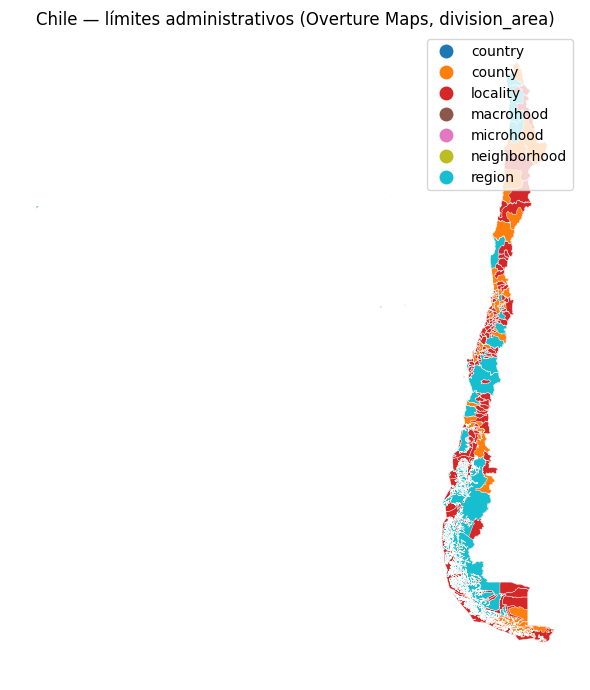

In [7]:
import matplotlib.pyplot as plt

# Encuadre al Chile continental: (minLon, maxLon, minLat, maxLat)
gdf_continental = gdf_chile.cx[-75.75:-66.42, -56.0:-17.5]

fig, ax = plt.subplots(figsize=(6, 12))
gdf_continental.plot(
    ax=ax,
    column="subtype",
    categorical=True,
    legend=True,
    edgecolor="white",
    linewidth=0.3,
    cmap="tab10",
)
ax.set_title("Chile — límites administrativos (Overture Maps, division_area)")
ax.set_axis_off()
plt.tight_layout()
plt.show()

## Paso 8 — Visualización interactiva

Con `gdf.explore()` (basado en Folium/Leaflet) obtenemos un mapa interactivo navegable dentro del propio notebook.

Para no sobrecargar el mapa, mostramos solo un nivel administrativo a la vez (por defecto, `region`).

In [8]:
nivel_a_mostrar = "region"  # cambia a "county" o "locality" según lo que exista en tus datos

gdf_nivel = gdf_chile[gdf_chile["subtype"] == nivel_a_mostrar]

gdf_nivel.explore(
    column="nombre",
    tooltip=["nombre", "subtype"],
    legend=False,
    cmap="tab20",
    style_kwds={"weight": 1},
)

## Paso 9 — Exportar por nivel administrativo

Guardamos un archivo separado por cada `subtype` presente (en Chile: `country`, `region`, `county`, `locality`, `neighborhood`, `microhood` y `macrohood`), tanto en GeoJSON (interoperable, ideal para web) como en GeoPackage (ideal para QGIS/análisis).

In [9]:
from pathlib import Path

carpeta_salida = Path("chile_limites_administrativos")
carpeta_salida.mkdir(exist_ok=True)

for subtype, grupo in gdf_chile.groupby("subtype"):
    nombre_archivo = f"chile_{subtype}"

    ruta_geojson = carpeta_salida / f"{nombre_archivo}.geojson"
    grupo.to_file(ruta_geojson, driver="GeoJSON")

    ruta_gpkg = carpeta_salida / f"{nombre_archivo}.gpkg"
    grupo.to_file(ruta_gpkg, driver="GPKG")

    print(f"{subtype}: {len(grupo)} polígonos -> {ruta_geojson.name}, {ruta_gpkg.name}")

c:\Users\Javiera\anaconda3\envs\pythongis\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


country: 1 polígonos -> chile_country.geojson, chile_country.gpkg
county: 56 polígonos -> chile_county.geojson, chile_county.gpkg
locality: 352 polígonos -> chile_locality.geojson, chile_locality.gpkg
macrohood: 1 polígonos -> chile_macrohood.geojson, chile_macrohood.gpkg
microhood: 110 polígonos -> chile_microhood.geojson, chile_microhood.gpkg
neighborhood: 390 polígonos -> chile_neighborhood.geojson, chile_neighborhood.gpkg
region: 16 polígonos -> chile_region.geojson, chile_region.gpkg


## Notas finales

**Jerarquía administrativa esperada para Chile en Overture:**

| subtype Overture | Equivalente en Chile | Cantidad aprox.* |
|---|---|---|
| `country` | País (Chile) | 1 |
| `region` | Región | 16 |
| `county` | Provincia | ~56 |
| `locality` | Comuna (aprox.) | 352 |

Overture también trae barrios con cobertura parcial: `neighborhood` (390), `microhood` (110) y `macrohood` (1).

\* Cantidades obtenidas en la ejecución del notebook. Chile tiene 346 comunas oficiales, así que las 352 `locality` no calzan 1:1: conviene validarlas contra la división oficial (BCN/INE) antes de usarlas como comunas. Las cantidades reales dependen de la cobertura de la fuente (principalmente OpenStreetMap) en cada release de Overture — siempre valida con `gdf_chile["subtype"].value_counts()` en lugar de asumir estos números.

**Buenas prácticas:**

- Fija siempre la `release` en tu script final para que los resultados sean reproducibles.
- Filtra en SQL (`WHERE`) y selecciona solo las columnas necesarias: DuckDB solo lee del Parquet remoto lo que la consulta requiere.
- Si vas a publicar o redistribuir los datos derivados, incluye la atribución: *"Contains data from Overture Maps Foundation, licensed under ODbL / CDLA-Permissive-2.0"*, mencionando además las fuentes originales cuando corresponda (p. ej. OpenStreetMap contributors).

**Referencias:**

- Overture Explorer (visor web): https://explore.overturemaps.org/
- Documentación del esquema `divisions`: https://docs.overturemaps.org/schema/reference/divisions/
- Guía de descargas y releases: https://docs.overturemaps.org/getting-data/
- Overture + DuckDB: https://docs.overturemaps.org/getting-data/duckdb/